**Tujuan dari model ini adalah mendeteksi batuk COVID. Recall dari kelas COVID adalah tujuan utama dari model ini.**

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
!unzip "/content/drive/MyDrive/!BinusMaterials/Sem 7/UTS ASP/Problem 2/Dataset2 Covid19 Cough.zip" -d "/content/extracted_data"

Archive:  /content/drive/MyDrive/!BinusMaterials/Sem 7/UTS ASP/Problem 2/Dataset2 Covid19 Cough.zip
replace /content/extracted_data/00014dcc-0f06-4c27-8c7b-737b18a2cf4c.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [26]:
import torch

if torch.cuda.is_available():
    print(f"GPU is active: {torch.cuda.get_device_name(0)}")
else:
    print("GPU is not active. Still using CPU.")

GPU is active: NVIDIA L4


In [194]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os
from tqdm import tqdm

import torchaudio
import torchcodec
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import copy

In [124]:
torch.manual_seed(42)

# Load Dataset

In [29]:
df = pd.read_csv("/content/extracted_data/metadata_compiled.csv")

In [30]:
df.head()

,uuid,datetime,cough_detected,SNR,latitude,longitude,age,gender,respiratory_condition,fever_muscle_pain,...,quality_4,cough_type_4,dyspnea_4,wheezing_4,stridor_4,choking_4,congestion_4,nothing_4,diagnosis_4,severity_4
0,00014dcc-0f06-4c27-8c7b-737b18a2cf4c,2020-11-25T18:58:50.488301+00:00,0.0155,7.326171,48.9,2.4,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00039425-7f3a-42aa-ac13-834aaa2b6b92,2020-04-13T21:30:59.801831+00:00,0.9609,16.151433,31.3,34.8,15.0,male,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0007c6f1-5441-40e6-9aaf-a761d8f2da3b,2020-10-18T15:38:38.205870+00:00,0.1643,16.217201,NaN,NaN,46.0,female,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0009eb28-d8be-4dc1-92bb-907e53bc5c7a,2020-04-12T04:02:18.159383+00:00,0.9301,20.146058,40.0,-75.1,34.0,male,True,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0012c608-33d0-4ef7-bde3-75a0b1a0024e,2020-04-15T01:03:59.029326+00:00,0.0482,0.000000,-16.5,-71.5,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
print(df.columns)

Index(['uuid', 'datetime', 'cough_detected', 'SNR', 'latitude', 'longitude',
       'age', 'gender', 'respiratory_condition', 'fever_muscle_pain', 'status',
       'quality_1', 'cough_type_1', 'dyspnea_1', 'wheezing_1', 'stridor_1',
       'choking_1', 'congestion_1', 'nothing_1', 'diagnosis_1', 'severity_1',
       'quality_2', 'cough_type_2', 'dyspnea_2', 'wheezing_2', 'stridor_2',
       'choking_2', 'congestion_2', 'nothing_2', 'diagnosis_2', 'severity_2',
       'quality_3', 'cough_type_3', 'dyspnea_3', 'wheezing_3', 'stridor_3',
       'choking_3', 'congestion_3', 'nothing_3', 'diagnosis_3', 'severity_3',
       'quality_4', 'cough_type_4', 'dyspnea_4', 'wheezing_4', 'stridor_4',
       'choking_4', 'congestion_4', 'nothing_4', 'diagnosis_4', 'severity_4'],
      dtype='object')


In [32]:
ROOT_DIR = '/content/extracted_data/'
CSV_PATH = '/content/extracted_data/metadata_compiled.csv'

In [33]:
df = df[["uuid", "status"]]
df.head()

,uuid,status
0,00014dcc-0f06-4c27-8c7b-737b18a2cf4c,NaN
1,00039425-7f3a-42aa-ac13-834aaa2b6b92,healthy
2,0007c6f1-5441-40e6-9aaf-a761d8f2da3b,healthy
3,0009eb28-d8be-4dc1-92bb-907e53bc5c7a,healthy
4,0012c608-33d0-4ef7-bde3-75a0b1a0024e,NaN


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27550 entries, 0 to 27549
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   uuid    27550 non-null  object
 1   status  16224 non-null  object
dtypes: object(2)
memory usage: 430.6+ KB


In [35]:
df_clean = df.dropna()

In [36]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16224 entries, 1 to 27548
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   uuid    16224 non-null  object
 1   status  16224 non-null  object
dtypes: object(2)
memory usage: 380.2+ KB


In [37]:
df_clean.head()

,uuid,status
1,00039425-7f3a-42aa-ac13-834aaa2b6b92,healthy
2,0007c6f1-5441-40e6-9aaf-a761d8f2da3b,healthy
3,0009eb28-d8be-4dc1-92bb-907e53bc5c7a,healthy
5,001328dc-ea5d-4847-9ccf-c5aa2a3f2d0f,healthy
7,001d8e33-a4af-4edb-98ba-b03f891d9a6c,COVID-19


In [38]:
df_clean["status"].unique()

array(['healthy', 'COVID-19', 'symptomatic'], dtype=object)

In [39]:
all_files = os.listdir(ROOT_DIR)
extensions = set(Path(f).suffix.lower() for f in all_files if os.path.isfile(os.path.join(ROOT_DIR, f)))

print("File formats found in directory:", extensions)

File formats found in directory: {'.ogg', '.json', '.webm', '.csv'}


In [65]:
data_dir = '/content/extracted_data'
all_files = os.listdir(data_dir)

audio_paths = {}

for f in all_files:
    if f.endswith('.webm') or f.endswith('.ogg'):
        uuid = f.rsplit('.', 1)[0]
        audio_paths[uuid] = os.path.join(data_dir, f)

df_clean['audio_path'] = df_clean['uuid'].map(audio_paths)

print(f"Total rows: {len(df_clean)}")
print(f"Rows with audio: {df_clean['audio_path'].count()}")

df_clean.head()

Total rows: 16224
Rows with audio: 16224


/tmp/ipykernel_1698/2290963564.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['audio_path'] = df_clean['uuid'].map(audio_paths)


,uuid,status,audio_path
1,00039425-7f3a-42aa-ac13-834aaa2b6b92,healthy,/content/extracted_data/00039425-7f3a-42aa-ac1...
2,0007c6f1-5441-40e6-9aaf-a761d8f2da3b,healthy,/content/extracted_data/0007c6f1-5441-40e6-9aa...
3,0009eb28-d8be-4dc1-92bb-907e53bc5c7a,healthy,/content/extracted_data/0009eb28-d8be-4dc1-92b...
5,001328dc-ea5d-4847-9ccf-c5aa2a3f2d0f,healthy,/content/extracted_data/001328dc-ea5d-4847-9cc...
7,001d8e33-a4af-4edb-98ba-b03f891d9a6c,COVID-19,/content/extracted_data/001d8e33-a4af-4edb-98b...


# Exploratory Data Analysis

**Jumlah data kelas COVID 19 jauh lebih sedikit dibandingkan data kelas sehat. Tidak heran jika nanti model akan bias ke data kelas sehat. **

In [ ]:
df_clean["status"].value_counts()

# Healthy: 12479
# Symptomatic: 2590
# COVID: 1155

,count
status,
healthy,12479
symptomatic,2590
COVID-19,1155


# Data preprocessing

# **Jawaban No a**
**Sampling rate semua audio adalah 48000. Zero padding dilakukan dengan cara menentukan Panjang audio maksimal. Panjang maksimal adalah 947520.**

In [70]:
sample_rates = []

for path in tqdm(df_clean['audio_path'], desc="Scanning sampling rates with TorchCodec"):
    decoder = torchcodec.decoders.AudioDecoder(path)
    sr = decoder.metadata.sample_rate
    sample_rates.append(sr)

sr_counts = pd.Series(sample_rates).value_counts()

print(sr_counts)

Scanning sampling rates with TorchCodec: 100%|██████████| 16224/16224 [00:14<00:00, 1136.16it/s]

48000    16224
Name: count, dtype: int64


In [43]:
max_len = 947520
sample_rate = 48000

# for path in tqdm(df_clean['audio_path'], desc="Checking audio lengths"):
#     waveform, sr = torchaudio.load(path)
#     if waveform.shape[1] > max_len:
#         max_len = waveform.shape[1]

# print(f"Sampling rate: {sample_rate} Hz")

In [44]:
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=sample_rate,
    melkwargs={"window_fn": torch.blackman_window}
)

mfcc_list = []

for path in tqdm(df_clean['audio_path'], desc="Extracting MFCCs"):
    waveform, sr = torchaudio.load(path)
    if waveform.shape[0] > 1:
        waveform = torch.mean(waveform, dim=0, keepdim=True)

    padding_size = max_len - waveform.shape[1]
    padded_waveform = F.pad(waveform, (0, padding_size))

    mfcc = mfcc_transform(padded_waveform)
    mfcc_list.append(mfcc)

/usr/local/lib/python3.13/dist-packages/torchaudio/functional/functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (128) may be set too high. Or, the value for `n_freqs` (201) may be set too low.
  warnings.warn(
Extracting MFCCs: 100%|██████████| 16224/16224 [07:46<00:00, 34.78it/s]


In [45]:
print(max_len)

947520


# **Jawaban No b**

In [46]:
y_labels = df_clean['status'].values

resize_transform = transforms.Resize((150, 150), antialias=True)
resized_mfccs = [resize_transform(mfcc) for mfcc in mfcc_list]

X = torch.stack(resized_mfccs)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_labels, test_size=0.20, random_state=42, stratify=y_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Training set: {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Validation set: {X_val.shape[0]} ({X_val.shape[0]/len(X)*100:.0f}%)")
print(f"Test set: {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.0f}%)")

Training set: 12979 (80%)
Validation set: 1622 (10%)
Test set: 1623 (10%)


In [68]:
os.makedirs('processed_data', exist_ok=True)
torch.save({'X': X_train, 'y': y_train}, 'processed_data/train_data.pt')
torch.save({'X': X_val, 'y': y_val}, 'processed_data/val_data.pt')
torch.save({'X': X_test, 'y': y_test}, 'processed_data/test_data.pt')

In [69]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_train_enc = torch.tensor(label_encoder.fit_transform(y_train), dtype=torch.long)
y_val_enc = torch.tensor(label_encoder.transform(y_val), dtype=torch.long)
y_test_enc = torch.tensor(label_encoder.transform(y_test), dtype=torch.long)
class_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))

In [81]:
batch_size = 128
train_dataset = TensorDataset(X_train, y_train_enc)
val_dataset = TensorDataset(X_val, y_val_enc)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataset = TensorDataset(X_test, y_test_enc)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Baseline Model Training and Evaluation

# **Jawaban No C**

In [128]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, ceil_mode=True)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 38 * 38, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = BaselineCNN()

In [129]:
total_params = sum(p.numel() for p in model.parameters())
print(total_params)

5968963


In [130]:
def train(model, train_loader, val_loader, epochs=30, learning_rate=0.001, patience=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)

    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': []
    }
    best_f1_score = 0.0
    epochs_without_improvement = 0
    save_path = "my_best_model.pth"

    print("Training...")
    for epoch in range(epochs):
        model.train()
        running_train_loss = 0.0
        train_preds = []
        train_targets = []

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            train_preds.extend(predicted.cpu().detach().numpy())
            train_targets.extend(labels.cpu().detach().numpy())

        avg_train_loss = running_train_loss / len(train_loader.dataset)
        train_acc = accuracy_score(train_targets, train_preds)
        train_f1 = f1_score(train_targets, train_preds, average='macro')

        # Validation
        model.eval()
        running_val_loss = 0.0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)

                _, predicted = torch.max(outputs, 1)
                all_preds.extend(predicted.cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

        avg_val_loss = running_val_loss / len(val_loader.dataset)

        val_acc = accuracy_score(all_targets, all_preds)
        val_f1 = f1_score(all_targets, all_preds, average='macro')

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

        if val_f1 > best_f1_score:
            best_f1_score = val_f1
            epochs_without_improvement = 0
            torch.save(model.state_dict(), save_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"\nStopping early at epoch {epoch+1}. No improvement in F1 for {patience} consecutive epochs.")
            break

    model.load_state_dict(torch.load(save_path))
    print(f"Training complete. Best validation F1: {best_f1_score:.4f}")

    return model, history

In [131]:
def test(model, test_loader, criterion, class_names):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()
    model.to(device)

    running_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    test_loss = running_loss / len(test_loader.dataset)
    test_acc = accuracy_score(all_targets, all_preds)
    test_f1 = f1_score(all_targets, all_preds, average='macro')

    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    print(f"Test F1-Macro: {test_f1:.4f}\n")

    print("Classification Report:")
    print(classification_report(all_targets, all_preds, target_names=class_names))

    cm = confusion_matrix(all_targets, all_preds)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)

    plt.title('Confusion Matrix')
    plt.ylabel('Actual Class')
    plt.xlabel('Predicted Class')
    plt.show()

In [132]:
baseline_model = BaselineCNN(num_classes=3)
best_model, history = train(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=30
)

Training...
Epoch [1/30] | Train Loss: 1.5173 | Val Loss: 0.7018 | Val Acc: 0.7694 | Val F1: 0.2899
Epoch [2/30] | Train Loss: 0.6964 | Val Loss: 0.7019 | Val Acc: 0.7694 | Val F1: 0.2899
Epoch [3/30] | Train Loss: 0.6906 | Val Loss: 0.6994 | Val Acc: 0.7694 | Val F1: 0.2899
Epoch [4/30] | Train Loss: 0.6845 | Val Loss: 0.6941 | Val Acc: 0.7694 | Val F1: 0.2899
Epoch [5/30] | Train Loss: 0.6762 | Val Loss: 0.6952 | Val Acc: 0.7694 | Val F1: 0.2899
Epoch [6/30] | Train Loss: 0.6666 | Val Loss: 0.6970 | Val Acc: 0.7688 | Val F1: 0.2898
Epoch [7/30] | Train Loss: 0.6498 | Val Loss: 0.7158 | Val Acc: 0.7694 | Val F1: 0.2899
Epoch [8/30] | Train Loss: 0.6335 | Val Loss: 0.7098 | Val Acc: 0.7651 | Val F1: 0.2890
Epoch [9/30] | Train Loss: 0.6089 | Val Loss: 0.7220 | Val Acc: 0.7589 | Val F1: 0.2926
Epoch [10/30] | Train Loss: 0.5831 | Val Loss: 0.7737 | Val Acc: 0.7503 | Val F1: 0.3014
Epoch [11/30] | Train Loss: 0.5460 | Val Loss: 0.7988 | Val Acc: 0.7515 | Val F1: 0.3042
Epoch [12/30] | Tr

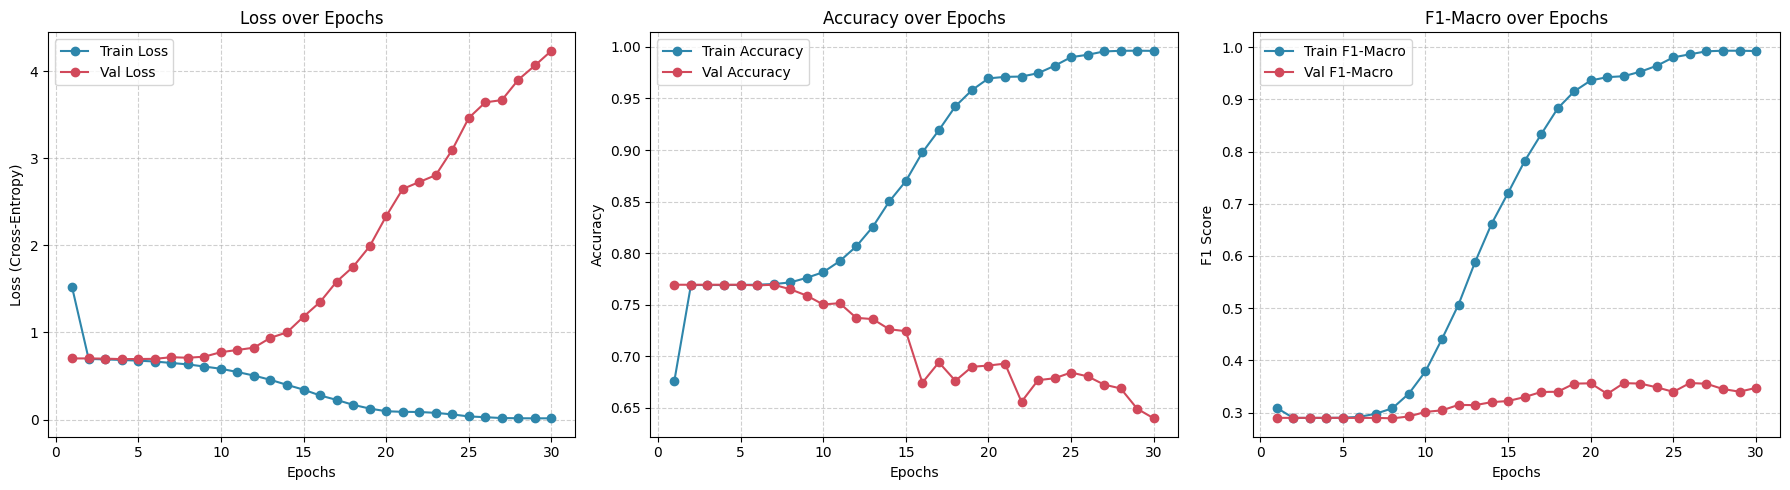

In [133]:
epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss', marker='o', color='#2e86ab')
plt.plot(epochs, history['val_loss'], label='Val Loss', marker='o', color='#d1495b')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Cross-Entropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 3, 2)
plt.plot(epochs, history['train_acc'], label='Train Accuracy', marker='o', color='#2e86ab')
plt.plot(epochs, history['val_acc'], label='Val Accuracy', marker='o', color='#d1495b')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 3, 3)
plt.plot(epochs, history['train_f1'], label='Train F1-Macro', marker='o', color='#2e86ab')
plt.plot(epochs, history['val_f1'], label='Val F1-Macro', marker='o', color='#d1495b')
plt.title('F1-Macro over Epochs')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Test Loss: 3.8566
Test Accuracy: 0.6808
Test F1-Macro: 0.3650

Classification Report:
              precision    recall  f1-score   support

    COVID-19       0.11      0.09      0.10       116
     healthy       0.78      0.85      0.81      1248
 symptomatic       0.22      0.15      0.18       259

    accuracy                           0.68      1623
   macro avg       0.37      0.36      0.37      1623
weighted avg       0.64      0.68      0.66      1623



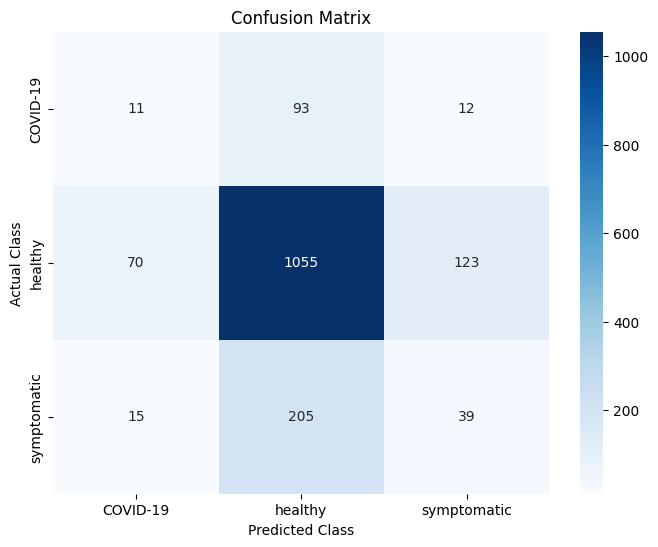

In [134]:
criterion = nn.CrossEntropyLoss()
test(best_model, test_loader, criterion, class_names=label_encoder.classes_)

# Kesimpulan
Model baseline sangatlah overfit. Model baseline juga biased ke kelas sehat.

# Improved Model Training and Evaluation

# **Jawaban No D**

# Penjelasan Model
Model improvement dilatihan dengan menggunakan augmentasi data untuk mengatasi jumlah kelas yang tidak seimbang. Weight juga diberikan terhadap kelas untuk mengatasi class imbalance. Selain itu, untuk mengatasi overfit maka digunakan dropout sehingga model bisa menggeneralisasi data dan mengurangi jarak antara train loss dan validation loss. Batch normalization dipakai agar gradien lebih stabil dan mencegah pembelajaran naik turun drastis pada setiap epoch. <br>

In [175]:
class AugmentedSpectrogramDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = X
        self.y = y
        self.augment = augment

        self.transform = transforms.Compose([
            transforms.RandomErasing(p=0.5, scale=(0.02, 0.1), ratio=(0.3, 3.3), value=0)
        ])

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        spectrogram = self.X[idx]
        label = self.y[idx]

        if self.augment:
            noise = torch.randn_like(spectrogram) * 0.05
            spectrogram = spectrogram + noise

            spectrogram = self.transform(spectrogram)

        return spectrogram, label

In [176]:
aug_train_dataset = AugmentedSpectrogramDataset(X_train, y_train_enc, augment=True)
val_dataset = AugmentedSpectrogramDataset(X_val, y_val_enc, augment=False)
test_dataset = AugmentedSpectrogramDataset(X_test, y_test_enc, augment=False)
batch_size = 128
train_loader = DataLoader(aug_train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [177]:
class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(ImprovedCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        flat_features = 41472

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [178]:
def train2(model, train_loader, val_loader, criterion, epochs=30, learning_rate=0.001, patience=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)

    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': []
    }
    best_f1_score = 0.0
    epochs_without_improvement = 0
    save_path = "my_best_model.pth"

    print("Training...")
    for epoch in range(epochs):
        model.train()
        running_train_loss = 0.0
        train_preds = []
        train_targets = []

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            train_preds.extend(predicted.cpu().detach().numpy())
            train_targets.extend(labels.cpu().detach().numpy())

        avg_train_loss = running_train_loss / len(train_loader.dataset)
        train_acc = accuracy_score(train_targets, train_preds)
        train_f1 = f1_score(train_targets, train_preds, average='macro')

        # Validation
        model.eval()
        running_val_loss = 0.0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * inputs.size(0)

                _, predicted = torch.max(outputs, 1)
                all_preds.extend(predicted.cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

        avg_val_loss = running_val_loss / len(val_loader.dataset)

        val_acc = accuracy_score(all_targets, all_preds)
        val_f1 = f1_score(all_targets, all_preds, average='macro')

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(train_f1)
        history['val_f1'].append(val_f1)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

        if val_f1 > best_f1_score:
            best_f1_score = val_f1
            epochs_without_improvement = 0
            torch.save(model.state_dict(), save_path)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"\nStopping early at epoch {epoch+1}. No improvement in F1 for {patience} consecutive epochs.")
            break

    model.load_state_dict(torch.load(save_path))
    print(f"Training complete. Best validation F1: {best_f1_score:.4f}")

    return model, history

In [188]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_enc.numpy()),
    y=y_train_enc.numpy()
)

smoothed_weights = np.sqrt(class_weights)
print(f"Smoothed Weights: {smoothed_weights}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights_tensor = torch.tensor(smoothed_weights, dtype=torch.float).to(device)
weighted_criterion = nn.CrossEntropyLoss(weight=weights_tensor)

improved_model = ImprovedCNN(num_classes=3)

best_model, history = train2(
    model=improved_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=weighted_criterion,
    epochs=50,
    learning_rate=1e-5,
    patience=10
)

Smoothed Weights: [2.16383431 0.65830849 1.4449909 ]
Training...
Epoch [1/50] | Train Loss: 1.1527 | Val Loss: 0.9744 | Val Acc: 0.7620 | Val F1: 0.3069
Epoch [2/50] | Train Loss: 1.0624 | Val Loss: 0.9842 | Val Acc: 0.7293 | Val F1: 0.3145
Epoch [3/50] | Train Loss: 1.0235 | Val Loss: 1.0406 | Val Acc: 0.5900 | Val F1: 0.3660
Epoch [4/50] | Train Loss: 0.9914 | Val Loss: 1.0395 | Val Acc: 0.6116 | Val F1: 0.3314
Epoch [5/50] | Train Loss: 0.9623 | Val Loss: 0.9941 | Val Acc: 0.6714 | Val F1: 0.3411
Epoch [6/50] | Train Loss: 0.9296 | Val Loss: 1.0015 | Val Acc: 0.6436 | Val F1: 0.3599
Epoch [7/50] | Train Loss: 0.9009 | Val Loss: 1.0125 | Val Acc: 0.7250 | Val F1: 0.3331
Epoch [8/50] | Train Loss: 0.8660 | Val Loss: 1.0435 | Val Acc: 0.6868 | Val F1: 0.3165
Epoch [9/50] | Train Loss: 0.8378 | Val Loss: 1.0306 | Val Acc: 0.5999 | Val F1: 0.3548
Epoch [10/50] | Train Loss: 0.8075 | Val Loss: 1.2432 | Val Acc: 0.2164 | Val F1: 0.1989
Epoch [11/50] | Train Loss: 0.7718 | Val Loss: 1.0740 

# **Jawaban No E**

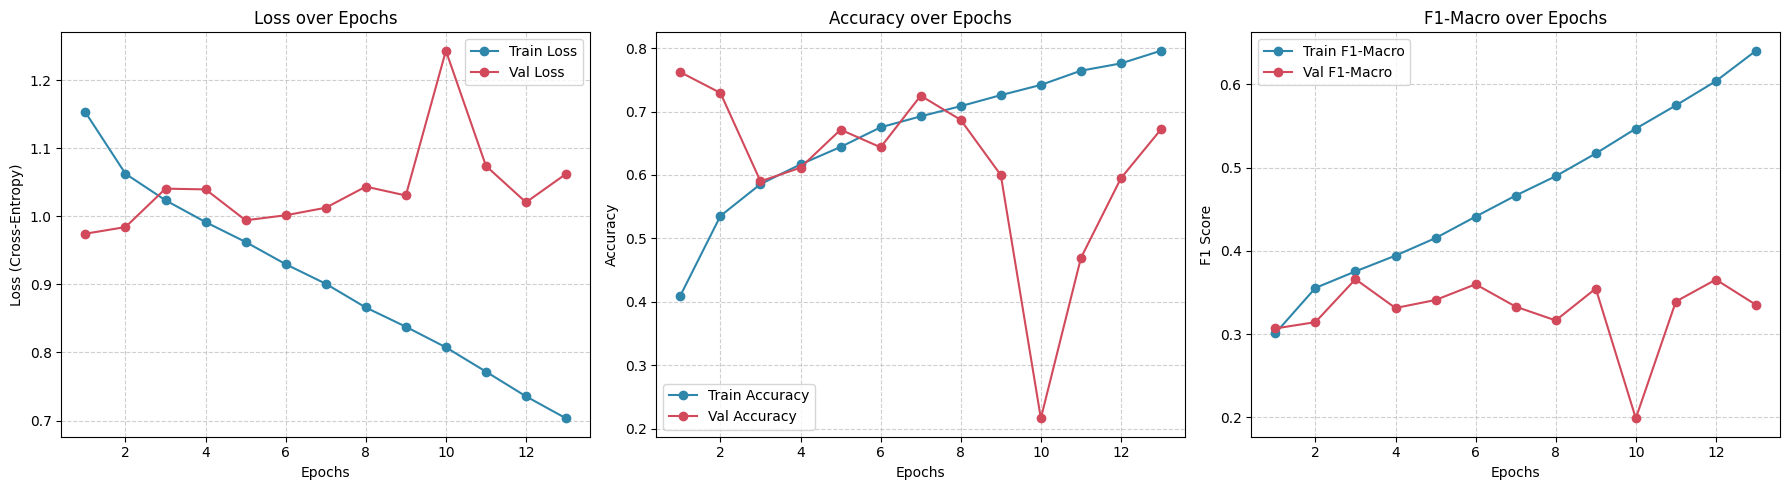

In [195]:
epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(epochs, history['train_loss'], label='Train Loss', marker='o', color='#2e86ab')
plt.plot(epochs, history['val_loss'], label='Val Loss', marker='o', color='#d1495b')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (Cross-Entropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 3, 2)
plt.plot(epochs, history['train_acc'], label='Train Accuracy', marker='o', color='#2e86ab')
plt.plot(epochs, history['val_acc'], label='Val Accuracy', marker='o', color='#d1495b')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 3, 3)
plt.plot(epochs, history['train_f1'], label='Train F1-Macro', marker='o', color='#2e86ab')
plt.plot(epochs, history['val_f1'], label='Val F1-Macro', marker='o', color='#d1495b')
plt.title('F1-Macro over Epochs')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Test Loss: 0.9860
Test Accuracy: 0.5866
Test F1-Macro: 0.3713

Classification Report:
              precision    recall  f1-score   support

    COVID-19       0.12      0.28      0.16       116
     healthy       0.79      0.69      0.74      1248
 symptomatic       0.21      0.21      0.21       259

    accuracy                           0.59      1623
   macro avg       0.37      0.39      0.37      1623
weighted avg       0.65      0.59      0.61      1623



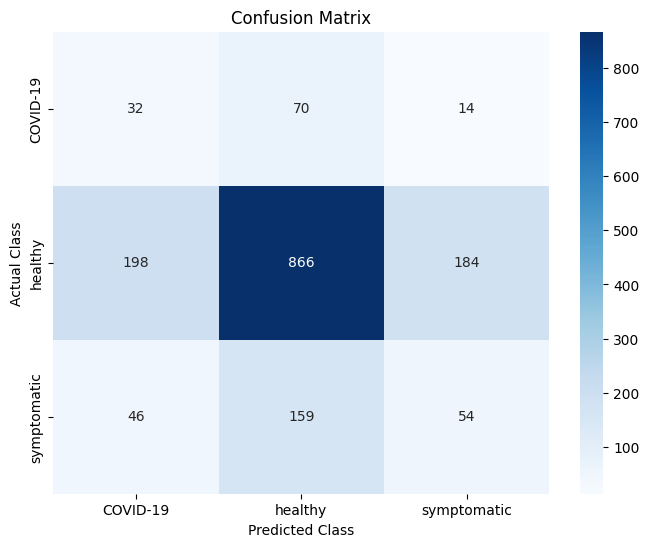

In [189]:
test(
    model=improved_model,
    test_loader=test_loader,
    criterion=nn.CrossEntropyLoss(),
    class_names=label_encoder.classes_
)

# **Kesimpulan Evaluasi**
Loss train dan validasi sangat dekat dibandingkan model baseline, namun akurasi dan f1 lebih buruk daripada model baseline. Model ini masih belum bisa mempelajari pola pada data. Hipotesis saya adalah diperlukannya lebih banyak data, terutama pada data kelas yang sangat minoritas. <br>
Class imbalance terhadap kelas healthy sudah berkurang namun belum sepenuhnya teratasi. Diperlukan data dimana kelasnya lebih seimbang.